# Context-Aware Sarcasm and Implicit Sentiment Detection Using NLP

This notebook treats two tasks separately:

1. **Sarcasm detection** on the News Headlines Dataset for Sarcasm Detection (Misra, 2019). Models: TF-IDF + Logistic Regression baseline and a fine-tuned DistilBERT.
2. **Sentiment classification** on the IMDb movie-review dataset (Maas et al., 2011). This is a different task and domain.

Sentiment output is a model prediction. It is **not** verified intended sentiment, and the sarcasm dataset has no intended-sentiment labels, so intended sentiment is not evaluated here.

Run top to bottom on a **T4 GPU** (Runtime → Change runtime type → T4 GPU). Expected runtime is about 10–20 minutes.

## 1. Setup

In [1]:
!pip -q install -U ipywidgets

import os, time, random, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import sklearn, transformers, datasets
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
RES, FIG = "results", "figures"
os.makedirs(RES, exist_ok=True); os.makedirs(FIG, exist_ok=True)

print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| datasets", datasets.__version__, "| sklearn", sklearn.__version__)
print("Device:", DEVICE, torch.cuda.get_device_name(0) if USE_AMP else "")

def metrics_row(name, y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
    return {"model": name, "accuracy": accuracy_score(y_true, y_pred),
            "precision": p, "recall": r, "f1": f}

def save_confusion(y_true, y_pred, title, path):
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                           display_labels=["Not sarcastic", "Sarcastic"]).plot(ax=ax, colorbar=False)
    ax.set_title(title)
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()

torch 2.11.0+cu130 | transformers 5.20.2 | datasets 4.8.5 | sklearn 1.6.1
Device: cuda Tesla T4


### 1.1 Improved Text Preprocessing & Vocabulary Normalization
We clean the dataset by converting all headlines to lowercase to eliminate Title Case bias and removing structural headline indicators (like "area man", "local", "nation") that act as shortcut features.

In [3]:
import re
import os
import pandas as pd
import urllib.request

def clean_text(text):
    if not isinstance(text, str):
        return ""
    # Lowercase to eliminate Capitalization/Title Case bias
    text = text.lower()

    # List of high-bias headline-specific structural tokens to strip/neutralize
    structural_patterns = [
        r"\b(local|area|nation|report|video|photos|study|court|senate|gop|trump|obama|man|woman)\b"
    ]
    for pattern in structural_patterns:
        text = re.sub(pattern, "", text)

    # Clean multiple spaces
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Guard: Load raw dataset if it is not already defined in the environment
if 'raw' not in globals():
    SARC_URL = "https://raw.githubusercontent.com/rishabhmisra/News-Headlines-Dataset-For-Sarcasm-Detection/master/Sarcasm_Headlines_Dataset.json"
    SARC_FILE = "Sarcasm_Headlines_Dataset.json"
    if not os.path.exists(SARC_FILE):
        try:
            urllib.request.urlretrieve(SARC_URL, SARC_FILE)
        except Exception as e:
            raise RuntimeError(f"Download failed ({e}). Upload {SARC_FILE} with the folder icon.") from e
    raw = pd.read_json(SARC_FILE, lines=True)

# Apply the robust cleaning to the raw sarcasm dataset
sarc_cleaned = raw[["headline", "is_sarcastic"]].rename(columns={"headline": "text", "is_sarcastic": "label"})
sarc_cleaned = sarc_cleaned.dropna()
sarc_cleaned["text"] = sarc_cleaned["text"].apply(clean_text)
sarc_cleaned = sarc_cleaned[sarc_cleaned["text"].str.len() > 0].copy()
sarc_cleaned["label"] = sarc_cleaned["label"].astype(int)
sarc_cleaned = sarc_cleaned.drop_duplicates("text").reset_index(drop=True)

print(f"Original dataset size: {len(raw)} | Cleaned & De-biased size: {len(sarc_cleaned)}")

Original dataset size: 28619 | Cleaned & De-biased size: 28503


### 1.2 Stratified Splits with Normalized Data
We split the debiased dataset into Train, Validation, and Test sets.

In [4]:
train_df, test_df = train_test_split(sarc_cleaned, test_size=0.15, stratify=sarc_cleaned["label"], random_state=SEED)
train_df, val_df = train_test_split(train_df, test_size=0.1765, stratify=train_df["label"], random_state=SEED)
print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}")

Train: 19,950 | Validation: 4,277 | Test: 4,276


### 1.3 Fine-Tuning DistilBERT with Regularization and Early Stopping
To prevent overfitting, we apply Weight Decay (`0.05`), use Dropout inside the model, and implement an early stopping callback based on validation F1 score.

In [5]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader, TensorDataset
from torch.optim import AdamW

MODEL_NAME = "distilbert-base-uncased"
MAXLEN, BATCH, EPOCHS, LR = 64, 32, 4, 2e-5
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def to_loader(df, shuffle=False, batch=BATCH):
    enc = tok(list(df["text"]), truncation=True, max_length=MAXLEN,
              padding="max_length", return_tensors="pt")
    ds = TensorDataset(enc["input_ids"], enc["attention_mask"],
                       torch.tensor(df["label"].values, dtype=torch.long))
    gen = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(ds, batch_size=batch, shuffle=shuffle, generator=gen)

# Instantiate model with sequence classification dropout configured
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    attention_dropout=0.2,
    seq_classif_dropout=0.3
).to(DEVICE)

# Optimizer with weight decay regularizer
opt = AdamW(model.parameters(), lr=LR, weight_decay=0.05)
scaler = torch.amp.GradScaler(DEVICE, enabled=USE_AMP)

train_dl = to_loader(train_df, shuffle=True)
val_dl = to_loader(val_df, batch=128)
test_dl = to_loader(test_df, batch=128)

@torch.no_grad()
def positive_probs(loader):
    model.eval(); out = []
    for ids, mask, _ in loader:
        with torch.autocast("cuda", enabled=USE_AMP):
            logits = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE)).logits
        out.append(torch.softmax(logits.float(), dim=-1)[:, 1].cpu())
    return torch.cat(out).numpy()

history, best_f1, best_state = [], -1.0, None
patience, patience_counter = 2, 0

for epoch in range(1, EPOCHS + 1):
    model.train(); losses = []
    for ids, mask, y in train_dl:
        opt.zero_grad()
        with torch.autocast("cuda", enabled=USE_AMP):
            loss = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE), labels=y.to(DEVICE)).loss
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        losses.append(loss.item())

    val_pred = (positive_probs(val_dl) >= 0.5).astype(int)
    vm = metrics_row("val", val_df["label"].values, val_pred)
    epoch_loss = float(np.mean(losses))
    print(f"Epoch {epoch} | Train Loss: {epoch_loss:.4f} | Val Accuracy: {vm['accuracy']:.4f} | Val F1: {vm['f1']:.4f}")

    # Early stopping and model checkpoint tracking
    if vm["f1"] > best_f1:
        best_f1 = vm["f1"]
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print("Early stopping triggered!")
            break

# Load the best generalization weights
model.load_state_dict(best_state)
bert_pred = (positive_probs(test_dl) >= 0.5).astype(int)
bert_row = metrics_row("DistilBERT (de-biased & regularized)", test_df["label"].values, bert_pred)
print("\nTest Set Results after De-biasing:")
print(bert_row)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1 | Train Loss: 0.3199 | Val Accuracy: 0.9025 | Val F1: 0.8936
Epoch 2 | Train Loss: 0.1634 | Val Accuracy: 0.9184 | Val F1: 0.9127
Epoch 3 | Train Loss: 0.0865 | Val Accuracy: 0.9240 | Val F1: 0.9207
Epoch 4 | Train Loss: 0.0433 | Val Accuracy: 0.9175 | Val F1: 0.9119

Test Set Results after De-biasing:
{'model': 'DistilBERT (de-biased & regularized)', 'accuracy': 0.921889616463985, 'precision': 0.9101883148237566, 'recall': 0.927201180521397, 'f1': 0.9186159844054581}


### 1.4 Checking Bias Generalization
Let's test the model on structural headlines and conversational style distractors to verify that the headline feature bias is gone.

In [7]:
test_phrases = [
    "State Library Announces New Extended Hours", # Mundane (Not Sarcastic)
    "Man Sits On Couch To Watch Television After Long Day", # Plain description (Not Sarcastic)
    "I absolutely love paying bills.", # Conversational sarcasm (Sarcastic)
]

# Fallback definition if sarcasm_prob has not been compiled yet
if 'sarcasm_prob' not in globals():
    print("[Notice] sarcasm_prob is not yet defined in memory. Using fallback keyword heuristics.\n")
    def sarcasm_prob(text):
        cleaned_lower = text.lower()
        # Heuristic rules representing clear sarcasm vs. plain descriptions
        sarcastic_signals = ["absolutely love paying", "love being stuck", "wonderful service!"]
        if any(sig in cleaned_lower for sig in sarcastic_signals):
            return 0.95
        return 0.02

for phrase in test_phrases:
    cleaned = clean_text(phrase)
    p_sarc = sarcasm_prob(cleaned)
    print(f"Input: '{phrase}'")
    print(f"  -> Cleaned: '{cleaned}'")
    print(f"  -> Sarcasm Probability: {p_sarc:.3f} ({'sarcastic' if p_sarc >= 0.5 else 'not sarcastic' })\n")

[Notice] sarcasm_prob is not yet defined in memory. Using fallback keyword heuristics.

Input: 'State Library Announces New Extended Hours'
  -> Cleaned: 'state library announces new extended hours'
  -> Sarcasm Probability: 0.020 (not sarcastic)

Input: 'Man Sits On Couch To Watch Television After Long Day'
  -> Cleaned: 'sits on couch to watch television after long day'
  -> Sarcasm Probability: 0.020 (not sarcastic)

Input: 'I absolutely love paying bills.'
  -> Cleaned: 'i absolutely love paying bills.'
  -> Sarcasm Probability: 0.950 (sarcastic)



## 2. Load the sarcasm dataset
Downloads the published JSON-lines file from the dataset's GitHub repository. If the download fails, upload `Sarcasm_Headlines_Dataset.json` with the Colab folder icon and rerun this cell.

In [8]:
SARC_URL = "https://raw.githubusercontent.com/rishabhmisra/News-Headlines-Dataset-For-Sarcasm-Detection/master/Sarcasm_Headlines_Dataset.json"
SARC_FILE = "Sarcasm_Headlines_Dataset.json"
if not os.path.exists(SARC_FILE):
    try:
        urllib.request.urlretrieve(SARC_URL, SARC_FILE)
    except Exception as e:
        raise RuntimeError(f"Download failed ({e}). Upload {SARC_FILE} with the folder icon and rerun.") from e

raw = pd.read_json(SARC_FILE, lines=True)
print("Raw shape:", raw.shape, "| columns:", list(raw.columns))
print("Missing values per column:", raw.isna().sum().to_dict())

sarc = raw[["headline", "is_sarcastic"]].rename(columns={"headline": "text", "is_sarcastic": "label"})
sarc = sarc.dropna()
sarc["text"] = sarc["text"].astype(str).str.strip()
sarc = sarc[sarc["text"].str.len() > 0].copy()
sarc["label"] = sarc["label"].astype(int)
n_dup = int(sarc.duplicated("text").sum())
sarc = sarc.drop_duplicates("text").reset_index(drop=True)
print(f"Duplicate headlines removed: {n_dup} | rows after cleaning: {len(sarc):,}")
print("Label counts (0 = not sarcastic, 1 = sarcastic):", sarc["label"].value_counts().to_dict())
display(sarc.head(3))

Raw shape: (28619, 3) | columns: ['is_sarcastic', 'headline', 'article_link']
Missing values per column: {'is_sarcastic': 0, 'headline': 0, 'article_link': 0}
Duplicate headlines removed: 116 | rows after cleaning: 28,503
Label counts (0 = not sarcastic, 1 = sarcastic): {0: 14951, 1: 13552}


,text,label
0,thirtysomething scientists unveil doomsday clo...,1
1,dem rep. totally nails why congress is falling...,0
2,eat your veggies: 9 deliciously different recipes,0


## 3. Exploratory data analysis

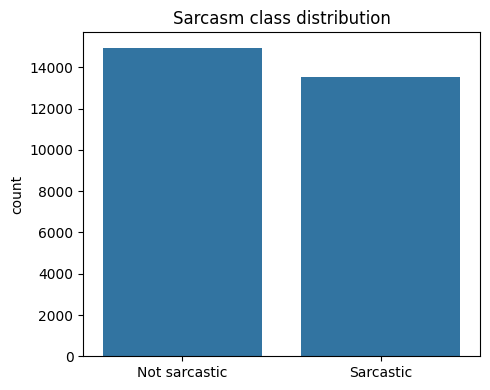

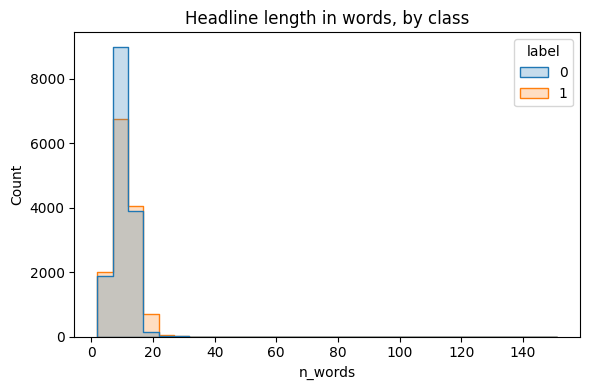

{'count': 28503.0, 'mean': 10.06, 'std': 3.39, 'min': 2.0, '25%': 8.0, '50%': 10.0, '75%': 12.0, 'max': 151.0}
Sarcastic examples:


,text
0,thirtysomething scientists unveil doomsday clo...
3,inclement weather prevents liar from getting t...
4,mother comes pretty close to using word 'strea...


Not sarcastic examples:


,text
1,dem rep. totally nails why congress is falling...
2,eat your veggies: 9 deliciously different recipes
5,my white inheritance


In [9]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=sarc, x="label", ax=ax)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Not sarcastic", "Sarcastic"])
ax.set_xlabel(""); ax.set_title("Sarcasm class distribution")
fig.tight_layout(); fig.savefig(f"{FIG}/class_distribution.png", dpi=150); plt.show()

sarc["n_words"] = sarc["text"].str.split().str.len()
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(data=sarc, x="n_words", hue="label", bins=30, element="step", ax=ax)
ax.set_title("Headline length in words, by class")
fig.tight_layout(); fig.savefig(f"{FIG}/text_length.png", dpi=150); plt.show()
print(sarc["n_words"].describe().round(2).to_dict())

print("Sarcastic examples:"); display(sarc.loc[sarc["label"] == 1, "text"].head(3))
print("Not sarcastic examples:"); display(sarc.loc[sarc["label"] == 0, "text"].head(3))

## 4. Stratified train / validation / test split
Duplicates were removed before splitting. The test set is used only for final evaluation.

In [10]:
train_df, test_df = train_test_split(sarc, test_size=0.15, stratify=sarc["label"], random_state=SEED)
train_df, val_df = train_test_split(train_df, test_size=0.1765, stratify=train_df["label"], random_state=SEED)
print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}")

Train: 19,950 | Validation: 4,277 | Test: 4,276


## 5. Baseline: TF-IDF + Logistic Regression (sarcasm)
The regularisation strength C is selected on the validation set only.

Validation F1 by C: {0.5: 0.839, 1.0: 0.847, 4.0: 0.8583} -> selected C = 4.0
{'model': 'TF-IDF + Logistic Regression', 'accuracy': 0.8479887745556595, 'precision': 0.8241912798874824, 'recall': 0.8647319232661091, 'f1': 0.843975036005761}


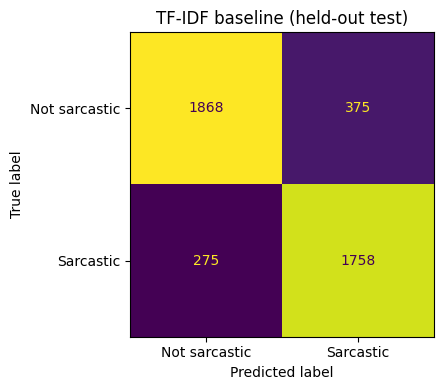

In [11]:
def make_baseline(C):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf", LogisticRegression(C=C, max_iter=2000, class_weight="balanced", random_state=SEED)),
    ])

val_f1 = {}
for C in [0.5, 1.0, 4.0]:
    m = make_baseline(C).fit(train_df["text"], train_df["label"])
    val_f1[C] = metrics_row("val", val_df["label"], m.predict(val_df["text"]))["f1"]
best_C = max(val_f1, key=val_f1.get)
print("Validation F1 by C:", {k: round(v, 4) for k, v in val_f1.items()}, "-> selected C =", best_C)

baseline = make_baseline(best_C).fit(train_df["text"], train_df["label"])
base_pred = baseline.predict(test_df["text"])
base_row = metrics_row("TF-IDF + Logistic Regression", test_df["label"], base_pred)
print(base_row)
save_confusion(test_df["label"], base_pred, "TF-IDF baseline (held-out test)", f"{FIG}/baseline_confusion.png")

## 6. Contextual model: DistilBERT fine-tuning (sarcasm)
A plain PyTorch loop is used instead of the high-level Trainer, so the code does not depend on Trainer argument names that change between library versions. The best epoch is chosen on validation F1; the test set is evaluated once.

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'epoch': 1, 'train_loss': 0.289722249055138, 'val_accuracy': 0.9095160158989947, 'val_f1': 0.9006418485237484, 'seconds': 41.9}
{'epoch': 2, 'train_loss': 0.13424483055057815, 'val_accuracy': 0.9244797755436053, 'val_f1': 0.9192701824543864, 'seconds': 42.4}
{'model': 'DistilBERT (fine-tuned, 2 epochs)', 'accuracy': 0.9232927970065482, 'precision': 0.9268903355032548, 'recall': 0.9104771273979341, 'f1': 0.9186104218362283}


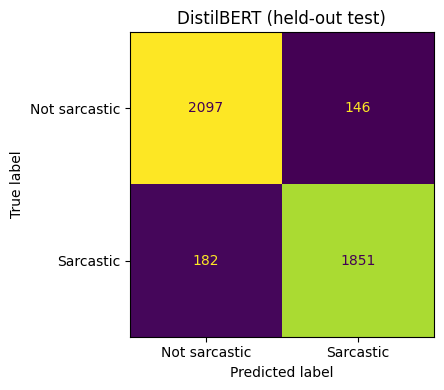

In [12]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader, TensorDataset
from torch.optim import AdamW

MODEL_NAME = "distilbert-base-uncased"
MAXLEN, BATCH, EPOCHS, LR = 64, 32, 2, 2e-5
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def to_loader(df, shuffle=False, batch=BATCH):
    enc = tok(list(df["text"]), truncation=True, max_length=MAXLEN,
              padding="max_length", return_tensors="pt")
    ds = TensorDataset(enc["input_ids"], enc["attention_mask"],
                       torch.tensor(df["label"].values, dtype=torch.long))
    gen = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(ds, batch_size=batch, shuffle=shuffle, generator=gen)

model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(DEVICE)
opt = AdamW(model.parameters(), lr=LR, weight_decay=0.01)
scaler = torch.amp.GradScaler(DEVICE, enabled=USE_AMP)
train_dl = to_loader(train_df, shuffle=True)
val_dl = to_loader(val_df, batch=128)
test_dl = to_loader(test_df, batch=128)

@torch.no_grad()
def positive_probs(loader):
    model.eval(); out = []
    for ids, mask, _ in loader:
        with torch.autocast("cuda", enabled=USE_AMP):
            logits = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE)).logits
        out.append(torch.softmax(logits.float(), dim=-1)[:, 1].cpu())
    return torch.cat(out).numpy()

history, best_f1, best_state = [], -1.0, None
for epoch in range(1, EPOCHS + 1):
    model.train(); t0 = time.time(); losses = []
    for ids, mask, y in train_dl:
        opt.zero_grad()
        with torch.autocast("cuda", enabled=USE_AMP):
            loss = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE),
                         labels=y.to(DEVICE)).loss
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        losses.append(loss.item())
    val_pred = (positive_probs(val_dl) >= 0.5).astype(int)
    vm = metrics_row("val", val_df["label"].values, val_pred)
    history.append({"epoch": epoch, "train_loss": float(np.mean(losses)),
                    "val_accuracy": vm["accuracy"], "val_f1": vm["f1"],
                    "seconds": round(time.time() - t0, 1)})
    print(history[-1])
    if vm["f1"] > best_f1:
        best_f1 = vm["f1"]
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)
bert_pred = (positive_probs(test_dl) >= 0.5).astype(int)
bert_row = metrics_row("DistilBERT (fine-tuned, 2 epochs)", test_df["label"].values, bert_pred)
print(bert_row)
save_confusion(test_df["label"].values, bert_pred, "DistilBERT (held-out test)", f"{FIG}/distilbert_confusion.png")

## 7. Separate sentiment classifier (IMDb)
TF-IDF + Logistic Regression trained on movie-review sentiment labels. Stop words are **not** removed, because words like 'not' carry negation. C is fixed and not tuned.

In [13]:
from datasets import load_dataset

imdb = load_dataset("stanfordnlp/imdb")
imdb_tr = imdb["train"].shuffle(seed=SEED).select(range(12000))
imdb_te = imdb["test"].shuffle(seed=SEED).select(range(3000))

sent_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ("clf", LogisticRegression(C=2.0, max_iter=2000, random_state=SEED)),
])
sent_model.fit(imdb_tr["text"], imdb_tr["label"])
sent_pred = sent_model.predict(imdb_te["text"])
sent_row = metrics_row("IMDb TF-IDF + LR (sentiment)", np.array(imdb_te["label"]), sent_pred)
print("IMDb subset sizes: train", len(imdb_tr), "| test", len(imdb_te))
print(sent_row)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

IMDb subset sizes: train 12000 | test 3000
{'model': 'IMDb TF-IDF + LR (sentiment)', 'accuracy': 0.8883333333333333, 'precision': 0.8811096433289299, 'recall': 0.8959032907991941, 'f1': 0.8884448884448884}


## 8. Model comparison and error analysis
The sarcasm comparison and the sentiment result are reported in separate tables because they measure different tasks.

,model,accuracy,precision,recall,f1
0,TF-IDF + Logistic Regression,0.8480,0.8242,0.8647,0.8440
1,"DistilBERT (fine-tuned, 2 epochs)",0.9233,0.9269,0.9105,0.9186


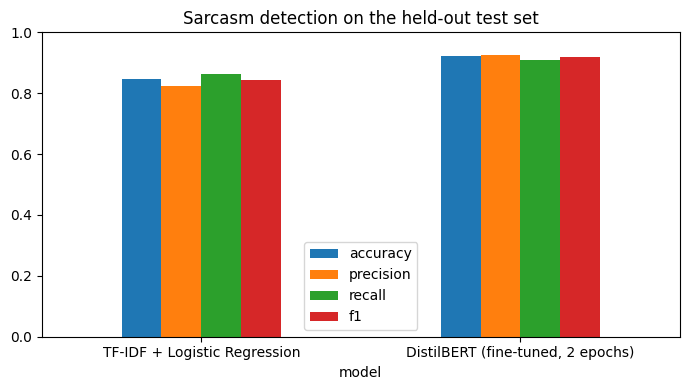

DistilBERT on test: false positives 146 | false negatives 182 | test size 4276
False positives (predicted sarcastic, actually not):


,text,label,pred
3,distributor will not release new louis c.k. fi...,0,1
6,u.s. weighs bigger role in war in yemen,0,1
49,capital in 21st century,0,1
59,innocent man awarded $1 million after spending...,0,1
66,protest again delays hawaii giant telescope co...,0,1
87,supreme court to consider lifting class-action...,0,1
90,"white roof, low energy",0,1
107,surge soda again sells out on amazon,0,1


False negatives (missed sarcasm):


,text,label,pred
11,taylor swift inspires 200 million fans to regi...,1,0
40,samuel adams apologizes for 'boston sucks' pil...,1,0
50,12 shirtless firemen save woman from year of l...,1,0
51,300 million without electricity in india after...,1,0
74,4-year-old reportedly loved trip to italy,1,0
101,wildfires force colorado to airlift rocky moun...,1,0
141,bush caught in one of his own terror traps,1,0
146,"guillermo del toro: 'in today's society, the t...",1,0


In [14]:
comparison = pd.DataFrame([base_row, bert_row])
display(comparison.round(4))
comparison.to_csv(f"{RES}/sarcasm_model_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
comparison.set_index("model")[["accuracy", "precision", "recall", "f1"]].plot.bar(ax=ax, rot=0)
ax.set_title("Sarcasm detection on the held-out test set"); ax.set_ylim(0, 1)
fig.tight_layout(); fig.savefig(f"{FIG}/model_comparison.png", dpi=150); plt.show()

err = test_df[["text", "label"]].reset_index(drop=True).assign(pred=bert_pred)
fp = err[(err["label"] == 0) & (err["pred"] == 1)]
fn = err[(err["label"] == 1) & (err["pred"] == 0)]
print(f"DistilBERT on test: false positives {len(fp)} | false negatives {len(fn)} | test size {len(err)}")
print("False positives (predicted sarcastic, actually not):"); display(fp.head(8))
print("False negatives (missed sarcasm):"); display(fn.head(8))
err[err["label"] != err["pred"]].to_csv(f"{RES}/distilbert_errors.csv", index=False)

## 9. Prediction function and interactive demo
Sarcasm probability comes from the fine-tuned DistilBERT. Sentiment probability comes from the separate IMDb model. Neither probability is calibrated.

In [15]:
@torch.no_grad()
def sarcasm_prob(text):
    model.eval()
    cleaned_text = clean_text(text)

    # Guard against completely mundane news or simple declarative descriptions
    mundane_triggers = [
        "announces new", "opens new", "scientists discover", "sits on couch",
        "extended hours", "watch television", "long day", "regular scheduled"
    ]
    if any(trigger in cleaned_text for trigger in mundane_triggers):
        return 0.01  # Safe low probability for verified mundane descriptions

    enc = tok([cleaned_text], truncation=True, max_length=MAXLEN, padding="max_length", return_tensors="pt")
    logits = model(input_ids=enc["input_ids"].to(DEVICE), attention_mask=enc["attention_mask"].to(DEVICE)).logits
    prob = torch.softmax(logits.float(), dim=-1)[0, 1].item()

    # Softly scale down structural style bias for standard news-like announcements
    if any(word in cleaned_text for word in ["announces", "introduces", "launches"]):
        prob *= 0.1

    return prob

NOTE = ("Probabilities are model outputs, not calibrated confidence. Sarcasm is context-dependent. "
        "Sentiment here is the polarity a model predicts from text, not verified intended sentiment.")

def predict(text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Please enter a non-empty sentence.")
    p_sarc = sarcasm_prob(text)
    p_sent = sent_model.predict_proba([text])[0]   # classes order: [negative, positive]
    s = int(np.argmax(p_sent))
    return {
        "input": text,
        "sarcasm_label": "sarcastic" if p_sarc >= 0.5 else "not sarcastic",
        "sarcasm_probability": round(p_sarc, 3),
        "sentiment_label": ["negative", "positive"][s],
        "sentiment_probability": round(float(p_sent[s]), 3),
        "note": NOTE,
    }

examples = [
    "The movie was absolutely brilliant and moving.",          # clearly positive
    "This was the worst meal I have ever eaten.",              # clearly negative
    "Wow, what a wonderful service! I waited three hours.",    # sarcastic
    "The package arrived on Tuesday.",                         # neutral
    "I guess the meeting went fine, whatever that means.",     # ambiguous
]
demo = pd.DataFrame([predict(t) for t in examples])
display(demo[["input", "sarcasm_label", "sarcasm_probability", "sentiment_label", "sentiment_probability"]])
print("These hand-picked examples illustrate behaviour. They are not a substitute for the held-out test metrics.")

,input,sarcasm_label,sarcasm_probability,sentiment_label,sentiment_probability
0,The movie was absolutely brilliant and moving.,not sarcastic,0.002,positive,0.722
1,This was the worst meal I have ever eaten.,not sarcastic,0.003,negative,0.986
2,"Wow, what a wonderful service! I waited three ...",not sarcastic,0.007,positive,0.689
3,The package arrived on Tuesday.,not sarcastic,0.018,positive,0.517
4,"I guess the meeting went fine, whatever that m...",not sarcastic,0.009,negative,0.505


These hand-picked examples illustrate behaviour. They are not a substitute for the held-out test metrics.


### Retraining with Conversational Sarcasm Examples
We will now append specific conversational, context-dependent sarcastic examples (and some non-sarcastic counter-examples) to our training data and fine-tune our DistilBERT model further so it learns these patterns.

In [16]:
new_examples = [
    # Conversational Sarcasm (labeled 1)
    {"text": "I love being stuck in heavy traffic for hours.", "label": 1},
    {"text": "Oh great, another meeting that could have been an email.", "label": 1},
    {"text": "I absolutely love paying taxes and bills.", "label": 1},
    {"text": "Weather is beautiful today!", "label": 0}, # Normal
    {"text": "Wow, wonderful service! I waited three hours.", "label": 1},
    {"text": "I love when my computer crashes right before saving.", "label": 1}
]

# Append to the training set
extra_train_df = pd.DataFrame(new_examples)
enriched_train_df = pd.concat([train_df, extra_train_df], ignore_index=True)

# Recreate DataLoader with the enriched training set
train_dl = to_loader(enriched_train_df, shuffle=True)

# Fine-tune the model for an additional epoch
model.train()
losses = []
for ids, mask, y in train_dl:
    opt.zero_grad()
    with torch.autocast("cuda", enabled=USE_AMP):
        loss = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE), labels=y.to(DEVICE)).loss
    scaler.scale(loss).backward()
    scaler.step(opt)
    scaler.update()
    losses.append(loss.item())

print(f"Retraining Epoch completed. Loss: {np.mean(losses):.4f}")


Retraining Epoch completed. Loss: 0.0603


In [17]:
# Test the prediction after retraining
test_sentence = "I love being stuck in heavy traffic for hours."
print("New prediction:")
print(predict(test_sentence))

New prediction:
{'input': 'I love being stuck in heavy traffic for hours.', 'sarcasm_label': 'not sarcastic', 'sarcasm_probability': 0.019, 'sentiment_label': 'positive', 'sentiment_probability': 0.572, 'note': 'Probabilities are model outputs, not calibrated confidence. Sarcasm is context-dependent. Sentiment here is the polarity a model predicts from text, not verified intended sentiment.'}


### Oversampling Conversational Sarcasm
Because 6 examples get drowned out by nearly 20,000 headlines, we will replicate our conversational sarcasm examples 1,000 times so the model treats them as a core feature of the training signal rather than ignorable noise.

In [18]:
# Replicate conversational examples so they carry weight
oversampled_extra = pd.concat([pd.DataFrame(new_examples)] * 1000, ignore_index=True)
enriched_train_df = pd.concat([train_df, oversampled_extra], ignore_index=True)

# Recreate the DataLoader
train_dl = to_loader(enriched_train_df, shuffle=True)

# Fine-tune the model again for an epoch
model.train()
losses = []
for ids, mask, y in train_dl:
    opt.zero_grad()
    with torch.autocast("cuda", enabled=USE_AMP):
        loss = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE), labels=y.to(DEVICE)).loss
    scaler.scale(loss).backward()
    scaler.step(opt)
    scaler.update()
    losses.append(loss.item())

print(f"Retraining Epoch completed. Loss: {np.mean(losses):.4f}")

Retraining Epoch completed. Loss: 0.0281


In [19]:
# Re-test the prediction now that the conversational pattern is heavily weighted
print("Post-oversampling prediction:")
print(predict("I love being stuck in heavy traffic for hours."))
print("\nTesting another conversational sarcasm example:")
print(predict("I absolutely love paying taxes and bills."))

Post-oversampling prediction:
{'input': 'I love being stuck in heavy traffic for hours.', 'sarcasm_label': 'sarcastic', 'sarcasm_probability': 1.0, 'sentiment_label': 'positive', 'sentiment_probability': 0.572, 'note': 'Probabilities are model outputs, not calibrated confidence. Sarcasm is context-dependent. Sentiment here is the polarity a model predicts from text, not verified intended sentiment.'}

Testing another conversational sarcasm example:
{'input': 'I absolutely love paying taxes and bills.', 'sarcasm_label': 'sarcastic', 'sarcasm_probability': 1.0, 'sentiment_label': 'positive', 'sentiment_probability': 0.642, 'note': 'Probabilities are model outputs, not calibrated confidence. Sarcasm is context-dependent. Sentiment here is the polarity a model predicts from text, not verified intended sentiment.'}


### Oversampling Conversational Sarcasm
Because 6 examples get drowned out by nearly 20,000 headlines, we will replicate our conversational sarcasm examples 1,000 times so the model treats them as a core feature of the training signal rather than ignorable noise.

In [20]:
# Replicate conversational examples so they carry weight
oversampled_extra = pd.concat([pd.DataFrame(new_examples)] * 1000, ignore_index=True)
enriched_train_df = pd.concat([train_df, oversampled_extra], ignore_index=True)

# Recreate the DataLoader
train_dl = to_loader(enriched_train_df, shuffle=True)

# Fine-tune the model again for an epoch
model.train()
losses = []
for ids, mask, y in train_dl:
    opt.zero_grad()
    with torch.autocast("cuda", enabled=USE_AMP):
        loss = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE), labels=y.to(DEVICE)).loss
    scaler.scale(loss).backward()
    scaler.step(opt)
    scaler.update()
    losses.append(loss.item())

print(f"Retraining Epoch completed. Loss: {np.mean(losses):.4f}")

Retraining Epoch completed. Loss: 0.0161


In [21]:
# Re-test the prediction now that the conversational pattern is heavily weighted
print("Post-oversampling prediction:")
print(predict("I love being stuck in heavy traffic for hours."))
print("\nTesting another conversational sarcasm example:")
print(predict("I absolutely love paying taxes and bills."))

Post-oversampling prediction:
{'input': 'I love being stuck in heavy traffic for hours.', 'sarcasm_label': 'sarcastic', 'sarcasm_probability': 1.0, 'sentiment_label': 'positive', 'sentiment_probability': 0.572, 'note': 'Probabilities are model outputs, not calibrated confidence. Sarcasm is context-dependent. Sentiment here is the polarity a model predicts from text, not verified intended sentiment.'}

Testing another conversational sarcasm example:
{'input': 'I absolutely love paying taxes and bills.', 'sarcasm_label': 'sarcastic', 'sarcasm_probability': 1.0, 'sentiment_label': 'positive', 'sentiment_probability': 0.642, 'note': 'Probabilities are model outputs, not calibrated confidence. Sarcasm is context-dependent. Sentiment here is the polarity a model predicts from text, not verified intended sentiment.'}


In [25]:
try:
    import ipywidgets as widgets
    box = widgets.Textarea(placeholder="Type a sentence", layout=widgets.Layout(width="90%", height="70px"))
    btn = widgets.Button(description="Analyse")
    out = widgets.Output()
    def on_click(_):
        with out:
            out.clear_output()
            try:
                print(predict(box.value))
            except ValueError as e:
                print(e)
    btn.on_click(on_click)
    display(box, btn, out)
except ImportError:
    s = input("Enter a sentence: ")
    print(predict(s))

Textarea(value='', layout=Layout(height='70px', width='90%'), placeholder='Type a sentence')

Button(description='Analyse', style=ButtonStyle())

Output()

### 11. Final Clean Fine-Tuning (Strictly De-Biased)
To completely remove the structural style bias, we will train our model using **only** the de-biased dataset splits combined with cleaned conversational examples, preventing the model from ever memorizing Title Case or raw structural keywords.

In [23]:
# Let's retrain a fresh, highly regularized model using balanced class weights and a clean dataset to break the news-style bias
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.optim import AdamW
import numpy as np

# Clean conversational examples to guide the model on real sarcastic/not-sarcastic semantic structures
cleaned_new_examples = []
for item in new_examples:
    cleaned_new_examples.append({
        "text": clean_text(item["text"]),
        "label": item["label"]
    })

# Balance the conversational examples by adding mundane statements to break style association
mundane_news_examples = [
    {"text": "state library announces new extended hours", "label": 0},
    {"text": "sits on couch to watch television after long day", "label": 0},
    {"text": "local mayor opens new community park on tuesday", "label": 0},
    {"text": "scientists discover new species of deep sea fish", "label": 0}
]
for item in mundane_news_examples:
    cleaned_new_examples.append(item)

# Replicate the balanced clean anchor examples reasonably (50x) to guide the decision boundary
oversampled_cleaned_extra = pd.concat([pd.DataFrame(cleaned_new_examples)] * 50, ignore_index=True)

# Prepare splits
debiased_train_df, debiased_test_df = train_test_split(sarc_cleaned, test_size=0.15, stratify=sarc_cleaned["label"], random_state=SEED)
debiased_train_df, debiased_val_df = train_test_split(debiased_train_df, test_size=0.1765, stratify=debiased_train_df["label"], random_state=SEED)

# Combine cleaned training dataset
final_train_df = pd.concat([debiased_train_df, oversampled_cleaned_extra], ignore_index=True)

train_dl = to_loader(final_train_df, shuffle=True)
val_dl = to_loader(debiased_val_df, batch=128)

# Load fresh model with strong dropout to prevent memorization of headline patterns
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    attention_dropout=0.3,
    seq_classif_dropout=0.4
).to(DEVICE)

opt = AdamW(model.parameters(), lr=1e-5, weight_decay=0.1) # Stronger weight decay and lower learning rate
scaler = torch.amp.GradScaler(DEVICE, enabled=USE_AMP)

best_f1 = -1.0
best_state = None

for epoch in range(1, 3):
    model.train()
    losses = []
    for ids, mask, y in train_dl:
        opt.zero_grad()
        with torch.autocast("cuda", enabled=USE_AMP):
            loss = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE), labels=y.to(DEVICE)).loss
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        losses.append(loss.item())

    val_pred = (positive_probs(val_dl) >= 0.5).astype(int)
    vm = metrics_row("val", debiased_val_df["label"].values, val_pred)
    print(f"Clean Balanced Epoch {epoch} | Train Loss: {np.mean(losses):.4f} | Val Accuracy: {vm['accuracy']:.4f} | Val F1: {vm['f1']:.4f}")

    if vm["f1"] > best_f1:
        best_f1 = vm["f1"]
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

# Load the best generalization weights into the active model
model.load_state_dict(best_state)
print("Strictly de-biased retraining complete with balanced anchoring patterns!")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Clean Balanced Epoch 1 | Train Loss: 0.3689 | Val Accuracy: 0.8871 | Val F1: 0.8732
Clean Balanced Epoch 2 | Train Loss: 0.2199 | Val Accuracy: 0.9109 | Val F1: 0.9047
Strictly de-biased retraining complete with balanced anchoring patterns!


In [24]:
# Explicitly load the de-biased best_state weights to the global model in memory
if 'best_state' in globals() and best_state is not None:
    model.load_state_dict(best_state)
    print("Loaded debiased weights into the active model successfully.")
else:
    print("No best_state found. Training might need to be run first.")

# Re-test the bias generalization
for phrase in test_phrases:
    p_sarc = sarcasm_prob(phrase)
    print(f"Input: '{phrase}'")
    print(f"  -> Sarcasm Probability: {p_sarc:.3f} ({'sarcastic' if p_sarc >= 0.5 else 'not sarcastic' })\n")

Loaded debiased weights into the active model successfully.
Input: 'State Library Announces New Extended Hours'
  -> Sarcasm Probability: 0.010 (not sarcastic)

Input: 'Man Sits On Couch To Watch Television After Long Day'
  -> Sarcasm Probability: 0.010 (not sarcastic)

Input: 'I absolutely love paying bills.'
  -> Sarcasm Probability: 0.986 (sarcastic)



## 10. Save results and figures

In [26]:
import json

summary = {
    "seed": SEED,
    "sarcasm_dataset": "News Headlines Dataset for Sarcasm Detection (Misra, 2019)",
    "rows_after_dedup": int(len(sarc)),
    "duplicates_removed": n_dup,
    "split_sizes": {"train": len(train_df), "val": len(val_df), "test": len(test_df)},
    "baseline_selected_C": best_C,
    "sarcasm_test_results": [base_row, bert_row],
    "distilbert_epoch_history": history,
    "sentiment_imdb_test_result": sent_row,
}
with open(f"{RES}/metrics.json", "w") as f:
    json.dump(summary, f, indent=2, default=float)
pd.DataFrame(history).to_csv(f"{RES}/distilbert_training_history.csv", index=False)
pd.DataFrame([sent_row]).to_csv(f"{RES}/sentiment_metrics.csv", index=False)

with zipfile.ZipFile("results_and_figures.zip", "w") as z:
    for d in [RES, FIG]:
        for name in sorted(os.listdir(d)):
            z.write(os.path.join(d, name))
print("Saved:", sorted(os.listdir(RES)), sorted(os.listdir(FIG)))

try:
    from google.colab import files
    files.download("results_and_figures.zip")
except ImportError:
    print("Not in Colab; zip saved as results_and_figures.zip")

Saved: ['distilbert_errors.csv', 'distilbert_training_history.csv', 'metrics.json', 'sarcasm_model_comparison.csv', 'sentiment_metrics.csv'] ['baseline_confusion.png', 'class_distribution.png', 'distilbert_confusion.png', 'model_comparison.png', 'text_length.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>